# 3. AGN tori, ionisation cones and jets

`System3D` composes scenes from named parts: **lamps** (point X-ray sources that also light everything else), opaque **bodies** (here a `Torus`) and optically thin **volumes** (here `BiCone`, `Shell`, `GasTorus`, `Jet`). In this notebook we build

1. a Seyfert nucleus: a corona, an opaque torus that Compton-reflects from its inner face, a clumpy broad-line region and ionisation cones that electron-scatter the nucleus;
2. a torus of *gas* instead, to follow the nucleus's transmitted spectrum with inclination, both smooth and clumpy;
3. a relativistic two-sided jet with knots, and its Doppler-boosted jet / counter-jet asymmetry.

All parameters are round numbers for illustration, not fits to particular sources.

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, PowerNorm

import xrimodel as xm
from xrimodel.engine import BiCone, GasTorus, Jet, Lamp, Scene, Shell, System3D, Torus
from xrimodel.units import UAS_PER_RAD

warnings.filterwarnings("ignore", message=".*electron-scattering optical depth.*")
corona = {"kind": "powerlaw", "gamma": 1.8, "norm": 0.02}
cmap = plt.get_cmap("magma").copy()
cmap.set_bad(cmap(0.0))   # black: no emission


def band_image(model, grid, lo, hi):
    tot = np.zeros(grid.n)
    for L in model.layers:
        if L.grid.n > 1:
            tot += xm.specmap_projection(L, edges=np.linspace(lo, hi, 41))[1]
    return grid.to_image(tot) / (grid.scale / UAS_PER_RAD) ** 2   # photons/s/cm2/sr


def extent(grid, unit=1.0):
    h = grid.nx / 2 * grid.scale / unit
    return [h, -h, -h, h]

## 1. A Seyfert nucleus

At 15 Mpc, 1 pc is 13.8 mas. The torus (major radius 0.6 pc, tube radius 0.3 pc) blocks lines of sight more than 60° from its axis. At 50° we therefore look over its near rim at the inner face of the far side, which is the only part the corona lights. The dashed line shows the torus's whole silhouette.

agn_blr0     1.02e-05 photons/s/cm^2
agn_blr1     1.66e-04 photons/s/cm^2
agn_blr2     2.99e-03 photons/s/cm^2
agn_blr3     9.04e-04 photons/s/cm^2
agn_cones0   1.07e-05 photons/s/cm^2
agn_cones1   2.05e-06 photons/s/cm^2
agn_cones2   1.91e-05 photons/s/cm^2
agn_cones3   7.36e-07 photons/s/cm^2
agn_torus    3.63e-03 photons/s/cm^2
agn_corona   6.21e-02 photons/s/cm^2


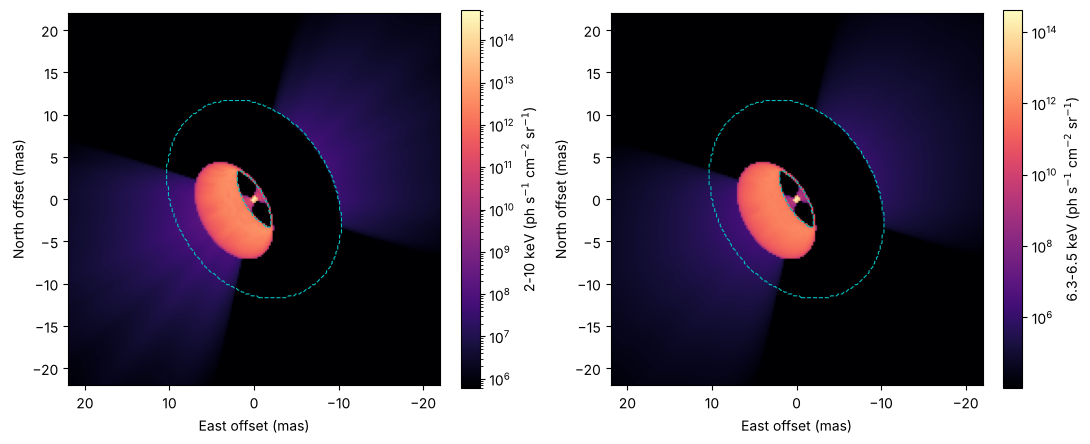

In [2]:
def seyfert(inclination, torus):
    return System3D(
        name="agn", length_unit="pc", inclination=inclination, node_pa=30.0, nh_ism=2e20,
        lamps=[Lamp(name="corona", spectrum=corona)], bodies=[torus], extent=3.2,
        volumes=[Shell(name="blr", r_in=0.005, r_out=0.03, n0=2e6, index=1.0, absorption="xi",
                       clumping={"f_vol": 0.05, "size": 0.15, "seed": 1},
                       lines=[{"e0": 6.4, "sigma": 0.03, "yield": 0.5}]),
                 BiCone(name="cones", r_in=0.05, r_out=3.0, half_angle=35.0, n0=3e4, index=2.0,
                        v_r=500.0, absorption="none")])


grid = xm.RegularGrid(nx=200, ny=200, scale=220.0)          # 0.22 mas pixels
scene = Scene(ra=182.6357, dec=39.4057, distance_pc=15.0e6, grid=grid)
scene.add(seyfert(50.0, Torus(name="torus", r_major=0.6, r_minor=0.3, albedo=0.1, mass_msun=4e7)))
agn = scene.render()
for L in agn.layers:
    print(f"{L.name:12s} {L.mean_photon_flux():.2e} photons/s/cm^2")

outline = Scene(ra=scene.ra, dec=scene.dec, distance_pc=scene.distance_pc, grid=grid)
outline.add(System3D(name="o", length_unit="pc", inclination=50.0, node_pa=30.0, supersample=1,
                     extent=3.2, bodies=[Torus(name="torus", r_major=0.6, r_minor=0.3,
                                               reflection=None,
                                               emission={"spectrum": corona, "intensity": 1.0})]))
silhouette = grid.to_image(outline.render().layer("o_torus_emit").maps["NORM"] > 0)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, (lo, hi), lab in [(ax[0], (2.0, 10.0), "2-10 keV"), (ax[1], (6.3, 6.5), "6.3-6.5 keV")]:
    img = band_image(agn, grid, lo, hi)
    pos = img[img > 0]
    im = a.imshow(np.where(img > 0, img, np.nan), origin="lower", extent=extent(grid, 1e3),
                  cmap=cmap, norm=LogNorm(vmin=np.percentile(pos, 1), vmax=pos.max()))
    a.contour(silhouette.astype(float), levels=[0.5], extent=extent(grid, 1e3), origin="lower",
              colors="c", linewidths=0.8, linestyles="--")
    a.set_xlabel("East offset (mas)"); a.set_ylabel("North offset (mas)")
    fig.colorbar(im, ax=a, label=f"{lab} (ph s$^{{-1}}$ cm$^{{-2}}$ sr$^{{-1}}$)", fraction=0.046)
fig.tight_layout()

### Through XRISALIS

Here we observe the nucleus at its model brightness (0.06 photons/s/cm²) for 5 ks. For illustration, we also observe the reprocessed light alone (torus, broad-line region, cones) for 50 ks, as if the corona's point-spread function had been removed. The instrument's field of view (~17 mas across for these baselines) does include the torus's lit face, but the cones extend beyond the FOV. These use `xri_helpers.observe` (see the quickstart).

292212 events (all), 96608 (reprocessed only)


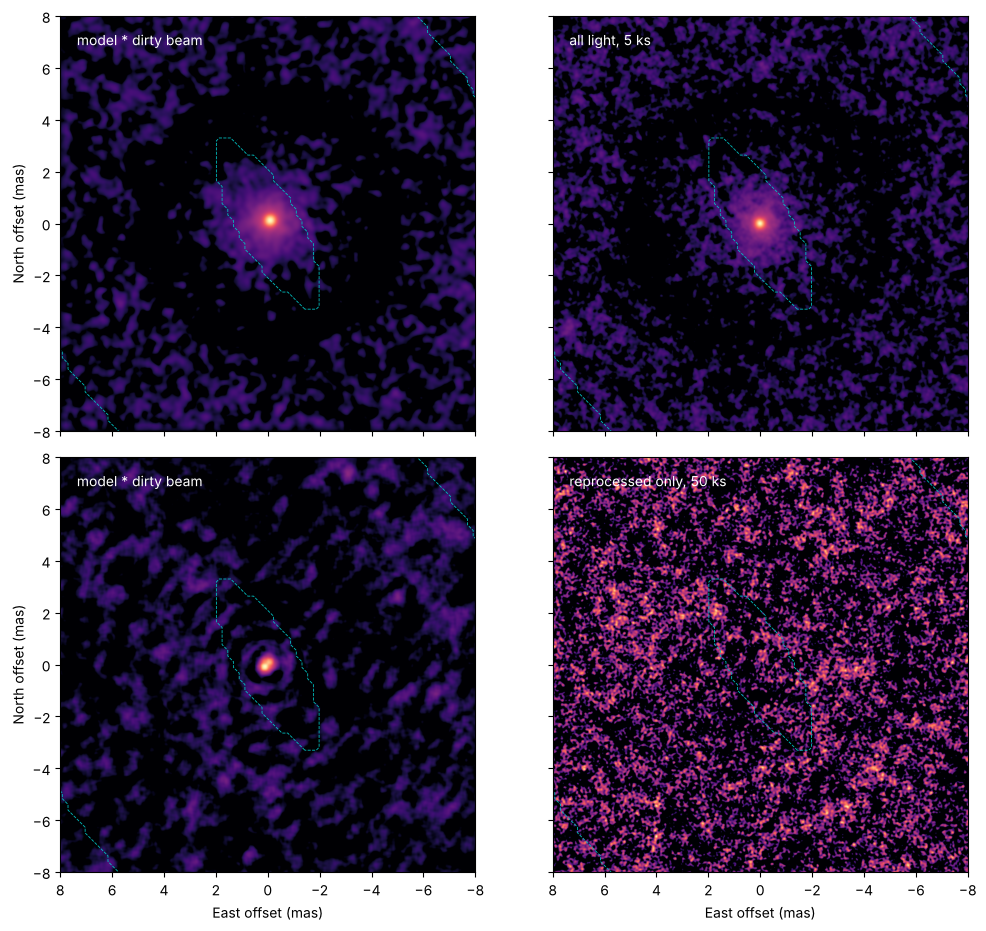

In [3]:
try:
    import xri_helpers as xri
except ImportError as err:   # XRISALIS not installed
    xri = None
    print("skipping:", err)

if xri is not None:
    reproc = xri.subset(agn, lambda n: n != "agn_corona")
    full = xri.observe(agn, 5000.0, fov_arcsec=0.016, seed=1)
    refl = xri.observe(reproc, 50000.0, fov_arcsec=0.016, seed=2)
    print(f"{len(full['events'])} events (all), {len(refl['events'])} (reprocessed only)")
    half = grid.nx / 2 * grid.scale
    fig, ax = plt.subplots(2, 2, figsize=(10, 9.2), sharex=True, sharey=True,
                           constrained_layout=True)
    for row, (obs, m, lab, g) in enumerate([(full, agn, "all light, 5 ks", 0.4),
                                             (refl, reproc, "reprocessed only, 50 ks", 0.6)]):
        pred = xri.predicted(xri.model_image(m, grid), half, obs, xri.dirty_beam(obs, 5000.0))
        xri.show(ax[row, 0], dict(obs, image=pred), unit=1e3, label="model * dirty beam", gamma=g)
        xri.show(ax[row, 1], obs, unit=1e3, label=lab, gamma=g)
        ax[row, 0].set_ylabel("North offset (mas)")
    for a in ax.flat:
        a.contour(silhouette.astype(float), levels=[0.5], extent=extent(grid, 1e3), origin="lower",
                  colors="c", linewidths=0.6, linestyles="--")
        a.set_xlim(8, -8); a.set_ylim(-8, 8)
    for a in ax[0]:
        a.set_xlabel("")

On the left we show the model convolved with the dirty beam (`xri.model_image`: the count rate per pixel, absorbed and weighted by the effective area), i.e. what the reconstruction should show without photon noise, and on the right the XRISALIS reconstructions (detected energies, deconvolved). The halo and the rings are the dirty beam's sidelobes, not structure in the source: the roll samples every baseline at all position angles, but nothing fills the gaps between the baseline lengths except bandwidth (see "How the roll samples the uv plane" in the quickstart).

This is also why the beam depends on the spectrum: the corona's continuum fills the gaps and smears the sidelobes, while the reprocessed light is dominated by the 6.4 keV line, whose nearly monochromatic beam keeps a ring around the core. For this reason `xri.dirty_beam` observes a point source with the model's own spectrum.

With all the light, the image is essentially the corona's point-spread function. The reprocessed light alone is lost in noise even in 50 ks: it is dominated by the 6.4 keV line, where the fringe orders are high and the detector's energy resolution decoheres most of the fringes, so the deconvolution has little signal left to recover. With an ideal detector (`use_true_energy=True`) the same photons show the broad-line region at the centre and the torus's lit inner face; imaging the reprocessed light of a nucleus like this one would need a much longer exposure or better energy resolution.

## 2. A torus of gas: transmission with inclination

An opaque body hides the nucleus completely beyond 60°. A `GasTorus` instead absorbs it: the nucleus's layer carries the absorbing column `NH` and the electron column `NE` along the line of sight, and the sampler removes photons by photoabsorption and by Klein-Nishina scattering out of the beam. Here we give the tube a Gaussian density profile with 3×10²⁴ cm⁻² through its middle (Compton-thick), and compare a smooth torus with a clumpy one (10% filling factor, same mean density).

Only the nucleus matters here, so we render the scene on a tiny grid.

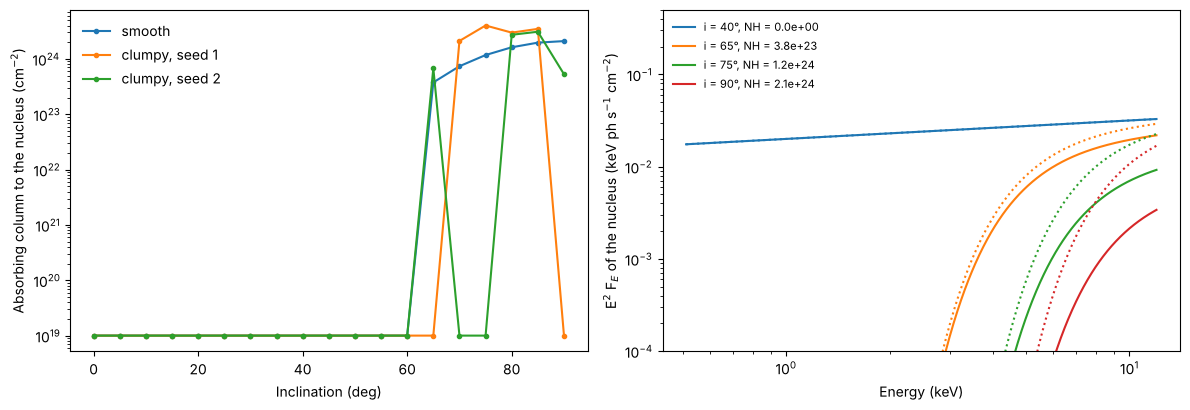

In [4]:
n0 = 3e24 / (0.6 * 3.0857e18 * 0.5 * np.sqrt(2 * np.pi) * 0.6827)   # NH through the tube middle
tiny = xm.RegularGrid(nx=4, ny=4, scale=2e4)
incs = np.arange(0.0, 90.1, 5.0)
cols = {}
for lab, clump in [("smooth", None), ("clumpy, seed 1", {"f_vol": 0.1, "size": 0.15, "seed": 1}),
                   ("clumpy, seed 2", {"f_vol": 0.1, "size": 0.15, "seed": 2})]:
    out = []
    for inc in incs:
        sc = Scene(ra=0.0, dec=0.0, distance_pc=15.0e6, grid=tiny)
        sc.add(System3D(name="t", length_unit="pc", inclination=float(inc),
                        lamps=[Lamp(name="corona", spectrum=corona)],
                        volumes=[GasTorus(name="torus", r_major=0.6, r_minor=0.3, n0=n0,
                                          profile="gaussian", clumping=clump)]))
        lamp = sc.render().layer("t_corona")
        out.append((lamp.maps["NH"][0], lamp.maps["NE"][0]))
    cols[lab] = np.array(out)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for lab, c in cols.items():
    ax[0].semilogy(incs, np.maximum(c[:, 0], 1e19), "o-", ms=3, label=lab)
ax[0].set_xlabel("Inclination (deg)"); ax[0].set_ylabel("Absorbing column to the nucleus (cm$^{-2}$)")
ax[0].legend(frameon=False)

e = xm.energy_grid(0.5, 12.0, 0.02)
ec = 0.5 * (e[1:] + e[:-1])
base = xm.powerlaw(e, 1.8, 0.02).values
for inc in (40.0, 65.0, 75.0, 90.0):
    nh, ne = cols["smooth"][int(inc / 5)]
    sig_abs = xm.format.spectra.sigma_photoabs(ec)
    sig_kn = xm.format.spectra.sigma_kn(ec)
    l, = ax[1].loglog(ec, ec**2 * base * np.exp(-nh * sig_abs - ne * sig_kn),
                      label=f"i = {inc:.0f}°, NH = {nh:.1e}")
    ax[1].loglog(ec, ec**2 * base * np.exp(-nh * sig_abs), ls=":", color=l.get_color())
ax[1].set_ylim(1e-4, 0.5)
ax[1].set_xlabel("Energy (keV)"); ax[1].set_ylabel("E$^2$ F$_E$ of the nucleus (keV ph s$^{-1}$ cm$^{-2}$)")
ax[1].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()

Solid lines include electron scattering out of the beam, dotted lines photoabsorption alone: at Compton-thick columns the scattering losses dominate above ~10 keV. Clumping makes the column a matter of chance, since some sightlines pass between clumps while others hit several.

The gas torus only scatters once, so its Compton *reflection* (many scatterings in thick gas) is not modelled. For that, keep the opaque `Torus` body, as in part 1.

### A Seyfert 2: the gas torus as a scene

Now we put a gas torus around a nucleus and look at it as an image. To keep the torus within the scales the interferometer can recover in hard X-rays (~1 mas at 6.4 keV, see the quickstart), we make it compact (major radius 0.1 pc, tube radius 0.05 pc, the same Compton-thick column through its middle as above, Keplerian about 4×10⁷ M☉) and put it at 60 Mpc, where it is ~1 mas across. The torus scatters the corona's light once and emits Fe Kα (yield 0.3 per scattered photon). At 75° we look at the nucleus through the tube: a Seyfert 2.

column to the nucleus: NH = 1.2e+24, NE = 1.4e+24 cm^-2


detected count rate: 0.150 counts/s, of which the nucleus 0.077


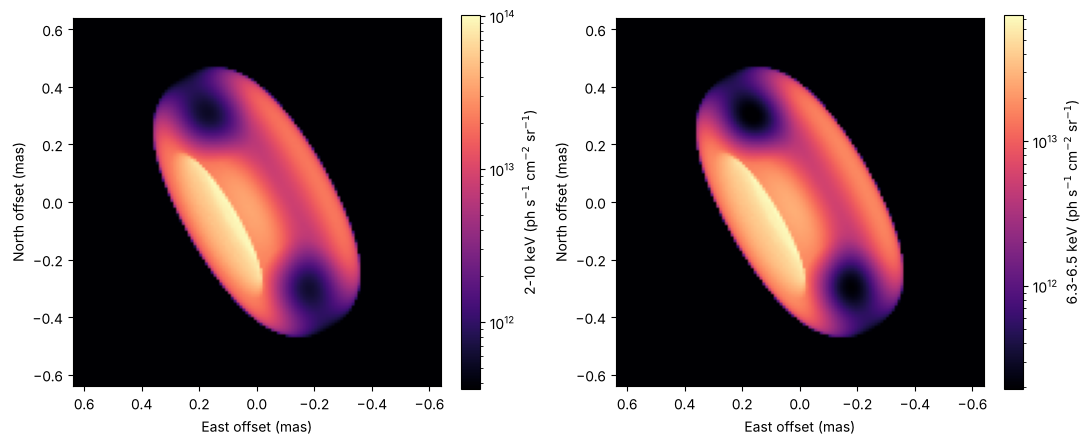

In [5]:
R_t, a_t = 0.1, 0.05                                                     # pc
n0_t = 3e24 / (2 * a_t * 3.0857e18 * 0.5 * np.sqrt(2 * np.pi) * 0.6827)   # as above
sy2_grid = xm.RegularGrid(nx=128, ny=128, scale=10.0)                    # 10 uas pixels
sc2 = Scene(ra=150.0, dec=20.0, distance_pc=60.0e6, grid=sy2_grid)
sc2.add(System3D(name="sy2", length_unit="pc", inclination=75.0, node_pa=30.0, nh_ism=2e20,
                 lamps=[Lamp(name="corona", spectrum=corona)], extent=0.25,
                 volumes=[GasTorus(name="torus", r_major=R_t, r_minor=a_t, n0=n0_t,
                                   profile="gaussian", mass_msun=4e7,
                                   lines=[{"e0": 6.4, "sigma": 0.01, "yield": 0.3}])]))
sy2 = sc2.render()
nuc = sy2.layer("sy2_corona")
print(f"column to the nucleus: NH = {nuc.maps['NH'][0]:.1e}, NE = {nuc.maps['NE'][0]:.1e} cm^-2")
rates = xri.model_image(sy2, sy2_grid) if xri is not None else None
if rates is not None:
    c = (sy2_grid.ny // 2, sy2_grid.nx // 2)
    print(f"detected count rate: {rates.sum():.3f} counts/s, of which the nucleus {rates[c]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, (lo, hi), lab in [(ax[0], (2.0, 10.0), "2-10 keV"), (ax[1], (6.3, 6.5), "6.3-6.5 keV")]:
    img = band_image(sy2, sy2_grid, lo, hi)
    pos = img[img > 0]
    im = a.imshow(np.where(img > 0, img, np.nan), origin="lower", extent=extent(sy2_grid, 1e3),
                  cmap=cmap, norm=LogNorm(vmin=np.percentile(pos, 1), vmax=pos.max()))
    a.set_xlabel("East offset (mas)"); a.set_ylabel("North offset (mas)")
    fig.colorbar(im, ax=a, label=f"{lab} (ph s$^{{-1}}$ cm$^{{-2}}$ sr$^{{-1}}$)", fraction=0.046)
fig.tight_layout()


Here we show the torus's scattered light (the nucleus itself, a point, is left out of these maps). The inner face of the far side, lit by the corona and seen over the near side of the tube, is brightest; the ends of the tube, seen edge-on through the most gas, are dark. The Fe Kα map follows the scattered continuum, since the line is emitted where the corona's light is scattered.

### Through XRISALIS at its real brightness

Here we observe the whole system for 500 ks. Even through 10²⁴ cm⁻², the nucleus still contributes about half of the detected counts (above ~6 keV the column is not opaque), so the image is a point source with the torus's scattered light around it.

67638 events in 500 ks


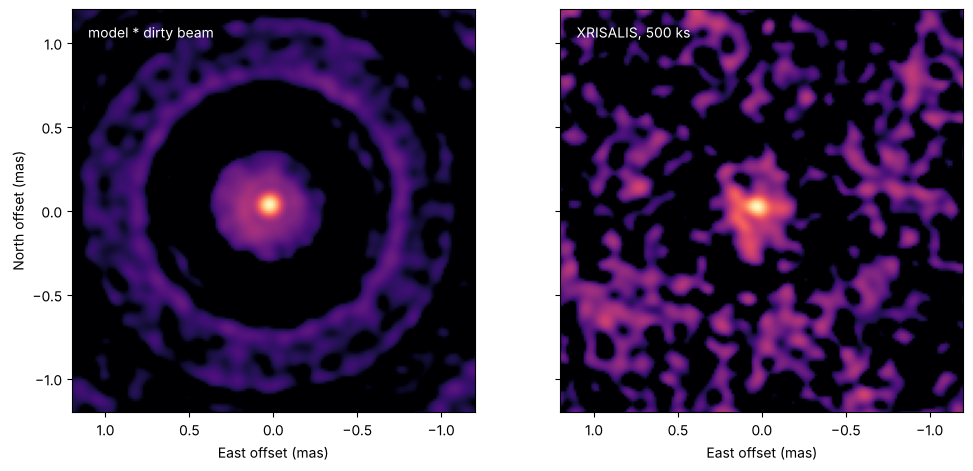

In [6]:
if xri is not None:
    half2 = sy2_grid.nx / 2 * sy2_grid.scale
    obs2 = xri.observe(sy2, 500e3, fov_arcsec=0.0026, seed=11)
    pred2 = xri.predicted(rates, half2, obs2, xri.dirty_beam(obs2, 20000.0))
    print(len(obs2["events"]), "events in 500 ks")
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True, constrained_layout=True)
    xri.show(ax[0], dict(obs2, image=pred2), unit=1e3, lim=1.2, label="model * dirty beam")
    xri.show(ax[1], obs2, unit=1e3, lim=1.2, label="XRISALIS, 500 ks")
    ax[0].set_ylabel("North offset (mas)")


The nucleus dominates both the prediction and the reconstruction: the torus's scattered light adds only a faint halo around the point source, and with ~68,000 events the detected energies leave little of even that. Obscured tori are faint, and their scattered light is hard (the soft X-rays are absorbed), which is exactly where the energy resolution decoheres the fringes the most.

### Through XRISALIS, for illustration

To see what the array could resolve if photons were not the limit, we now observe the torus's own light alone (as if the nucleus's point-spread function had been removed), ten times brighter, for 500 ks. We show the model's count-rate image, its convolution with the dirty beam, and reconstructions with an ideal detector (true energies) and with the detected energies.

356453 events in 500 ks


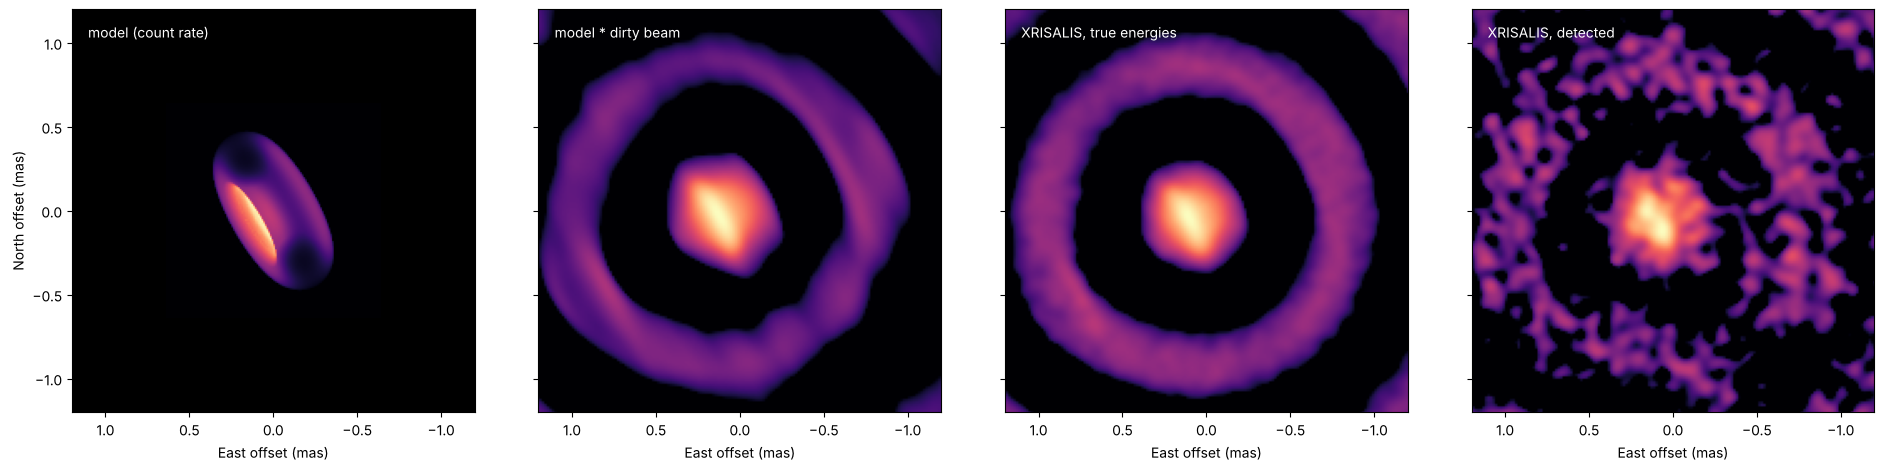

In [7]:
if xri is not None:
    torus_only = xri.subset(sy2, lambda n: n != "sy2_corona")
    f10 = 10 * sum(L.mean_photon_flux() for L in torus_only.layers)
    obs3 = xri.observe(torus_only, 500e3, fov_arcsec=0.0026, total_flux=f10, seed=12)
    ideal3 = xri.observe(torus_only, 500e3, fov_arcsec=0.0026, total_flux=f10, seed=12,
                         use_true_energy=True)
    truth3 = xri.model_image(torus_only, sy2_grid)
    pred3 = xri.predicted(truth3, half2, obs3, xri.dirty_beam(obs3, 20000.0))
    print(len(obs3["events"]), "events in 500 ks")
    fig, ax = plt.subplots(1, 4, figsize=(19, 4.6), sharey=True, constrained_layout=True)
    h2 = half2 / 1e3
    ax[0].imshow(truth3 / truth3.max(), origin="lower", extent=[h2, -h2, -h2, h2], cmap="magma",
                 norm=PowerNorm(0.5, vmin=0, vmax=1))
    ax[0].set_facecolor("black")
    ax[0].text(0.04, 0.93, "model (count rate)", transform=ax[0].transAxes, color="w")
    ax[0].set_xlabel("East offset (mas)")
    xri.show(ax[1], dict(obs3, image=pred3), unit=1e3, label="model * dirty beam")
    xri.show(ax[2], ideal3, unit=1e3, label="XRISALIS, true energies")
    xri.show(ax[3], obs3, unit=1e3, label="XRISALIS, detected")
    for a in ax:
        a.set_xlim(1.2, -1.2); a.set_ylim(-1.2, 1.2)
    ax[0].set_ylabel("North offset (mas)")


With ~360,000 events the torus is resolved, if only just: the lit inner face (~0.6 mas long) comes out as a core elongated along it, both in the prediction and in the reconstruction from the detected energies, while the rest of the torus and its dark ends are below the resolution (~190 µas). The ring at ~1 mas is the dirty beam's sidelobe, as in part 1. The ideal-detector image has less noise, but its core is rounder: its beam is not the deconvolved one used for the prediction.

So imaging an obscured torus needs both a compact torus (within the ~1 mas recoverable in hard X-rays) and many photons: a bright, nearby Compton-thick nucleus, long exposures, or more collecting area.

## 3. A relativistic jet

Here we model a microquasar-like jet (Lorentz factor 2, half-opening angle 4°) at 60° to the line of sight, 2 kpc away, with three knots on each side moving with the flow. A steady jet's band photon flux scales as the Doppler factor squared, and a moving knot's as its cube, so the approaching side is brighter by ((1 + β cos i)/(1 − β cos i))² for the jet and the cube of that for the knots.

jet / counter-jet flux ratio 6.8; steady jet alone 6.4, knots alone 16.1
G approaching 0.882, receding 0.349


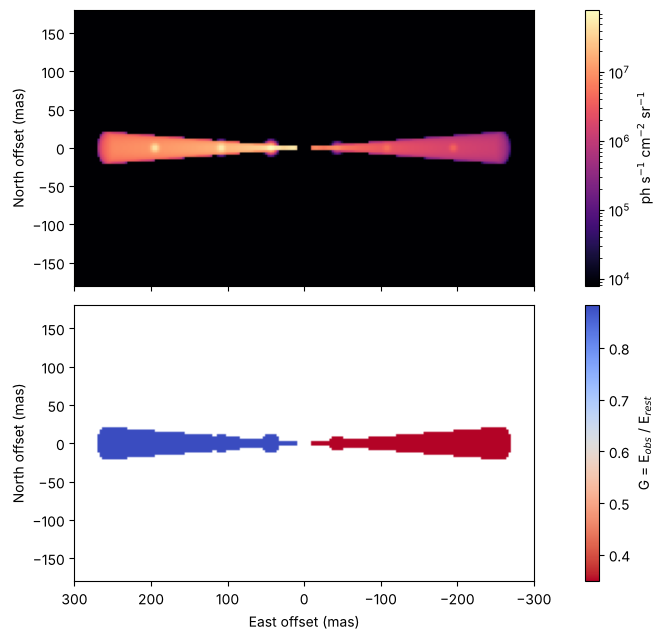

In [8]:
gam, inc = 2.0, 60.0
beta = np.sqrt(1 - 1 / gam**2)
jet = Jet(name="jet", r0=5.0, r1=600.0, half_angle=4.0, index=2.0, lorentz=gam, n0=1.0,
          knots=[{"r": r, "size": 6.0, "j": 3e-7} for r in (100.0, 250.0, 450.0)],
          emission={"spectrum": {"kind": "powerlaw", "gamma": 1.7, "norm": 1.0}, "j0": 1e-4},
          n_fine=4096)
jgrid = xm.RegularGrid(nx=200, ny=120, scale=3000.0)   # 3 mas pixels (1 AU = 0.5 mas at 2 kpc)
sc = Scene(ra=0.0, dec=0.0, distance_pc=2000.0, grid=jgrid)
sc.add(System3D(name="mq", length_unit="AU", inclination=inc, node_pa=0.0, volumes=[jet],
                chunk=1024))
jm = sc.render()
lay = [L for L in jm.layers if L.name.startswith("mq_jet_emit")]
w = sum(L.maps["NORM"] for L in lay)
gmap = sum(L.maps["NORM"] * L.maps["G"] for L in lay) / np.where(w > 0, w, 1)
x, y = jgrid.centres()

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
img = jgrid.to_image(w) / (jgrid.scale / UAS_PER_RAD) ** 2
ext_j = [jgrid.nx / 2 * jgrid.scale / 1e3, -jgrid.nx / 2 * jgrid.scale / 1e3,
         -jgrid.ny / 2 * jgrid.scale / 1e3, jgrid.ny / 2 * jgrid.scale / 1e3]
im = ax[0].imshow(np.where(img > 0, img, np.nan), origin="lower", extent=ext_j, cmap=cmap,
                  norm=LogNorm(vmin=img.max() * 1e-4, vmax=img.max()))
fig.colorbar(im, ax=ax[0], label="ph s$^{-1}$ cm$^{-2}$ sr$^{-1}$", fraction=0.03)
im = ax[1].imshow(jgrid.to_image(np.where(w > 1e-4 * w.max(), gmap, np.nan)), origin="lower",
                  extent=ext_j,
                  cmap="coolwarm_r")
fig.colorbar(im, ax=ax[1], label="G = E$_{obs}$ / E$_{rest}$", fraction=0.03)
for a in ax:
    a.set_ylabel("North offset (mas)")
ax[1].set_xlabel("East offset (mas)")
fig.tight_layout()

mu = beta * np.cos(np.deg2rad(inc))
print(f"jet / counter-jet flux ratio {w[x > 0].sum() / w[x < 0].sum():.1f}; steady jet alone "
      f"{((1 + mu) / (1 - mu)) ** 2:.1f}, knots alone {((1 + mu) / (1 - mu)) ** 3:.1f}")
print(f"G approaching {1 / (gam * (1 - mu)):.3f}, receding {1 / (gam * (1 + mu)):.3f}")

With `node_pa=0` the approaching jet projects to the East (left). The measured ratio lies between the steady-jet and knot values because both contribute. The jet's own emission could also light the rest of the scene: `emission["illuminates"]` turns it into a set of point illuminators drawn from its emissivity.

### Through XRISALIS

The jet above is ~500 mas long, far beyond the instrument's ~17 mas field of view. For a simulation we therefore scale the same kind of jet down: 0.3-12 AU (reaching ~6 mas from the core at 2 kpc), with knots at 3, 6 and 9 AU, scaled to 0.03 photons/s/cm² and observed for 5 ks.

132951 events


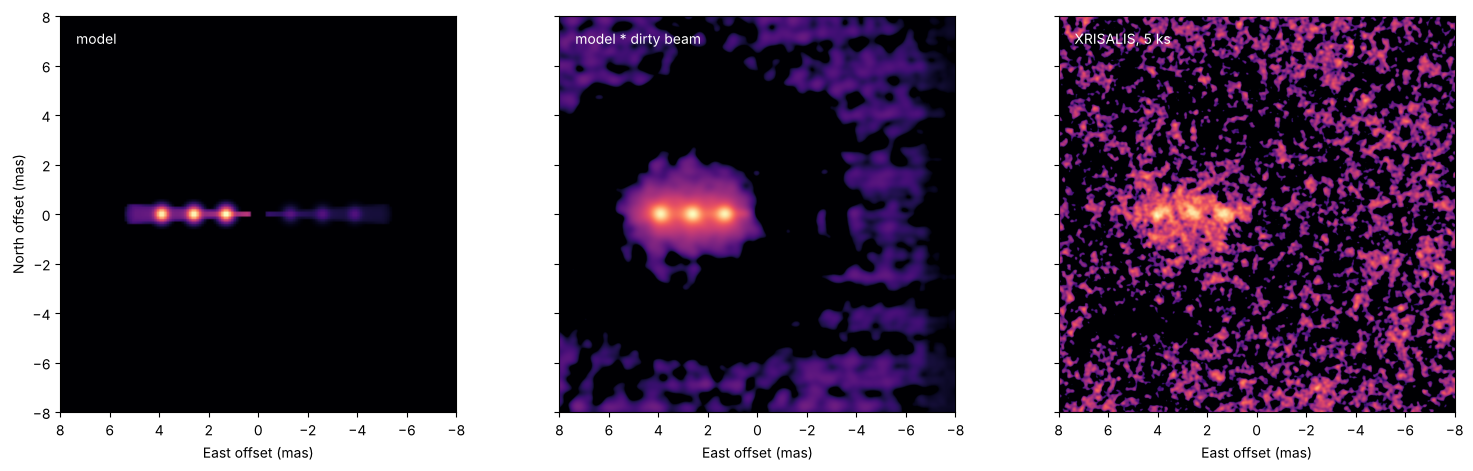

In [9]:
if xri is not None:
    small = Jet(name="jet", r0=0.3, r1=12.0, half_angle=4.0, index=2.0, lorentz=gam, n0=1.0,
                knots=[{"r": r, "size": 0.3, "j": 4e-6} for r in (3.0, 6.0, 9.0)],
                emission={"spectrum": {"kind": "powerlaw", "gamma": 1.7, "norm": 1.0}, "j0": 1e-4},
                n_fine=4096)
    sgrid = xm.RegularGrid(nx=160, ny=160, scale=100.0)    # 0.1 mas pixels
    sc = Scene(ra=0.0, dec=0.0, distance_pc=2000.0, grid=sgrid)
    sc.add(System3D(name="mq", length_unit="AU", inclination=inc, node_pa=0.0, volumes=[small],
                    chunk=1024))
    jm_small = sc.render()
    obs = xri.observe(jm_small, 5000.0, fov_arcsec=0.016, total_flux=0.03, seed=3)
    print(len(obs["events"]), "events")
    truth = xri.model_image(jm_small, sgrid)
    pred = xri.predicted(truth, sgrid.nx / 2 * sgrid.scale, obs, xri.dirty_beam(obs, 5000.0))
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True, constrained_layout=True)
    hs = sgrid.nx / 2 * sgrid.scale / 1e3
    ax[0].imshow(truth / truth.max(), origin="lower", extent=[hs, -hs, -hs, hs], cmap="magma",
                 norm=PowerNorm(0.4, vmin=0, vmax=1))
    ax[0].text(0.04, 0.93, "model", transform=ax[0].transAxes, color="w")
    ax[0].set_xlabel("East offset (mas)"); ax[0].set_ylabel("North offset (mas)")
    xri.show(ax[1], dict(obs, image=pred), unit=1e3, label="model * dirty beam", gamma=0.4)
    xri.show(ax[2], obs, unit=1e3, label="XRISALIS, 5 ks", gamma=0.4)
    for a in ax:
        a.set_xlim(8, -8); a.set_ylim(-8, 8)

The reconstruction recovers the one-sidedness of the jet (Doppler boosting) and the knots on the approaching side at ~190 µas resolution, although with the detected energies the image is much noisier than the noise-free prediction in the middle panel. As that panel shows, the structure beyond ~5 mas is the dirty beam's sidelobes.